In [2]:
import pandas as pd

In [3]:

df = pd.read_csv("../data/onlinefraud.csv")

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.shape

(6362620, 11)

In [5]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [7]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [8]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [9]:
df.duplicated().sum()

np.int64(0)

Fraud Distribution Analysis

In [10]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [11]:
df["isFraud"].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In [12]:
# Analyze Transaction Types

df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

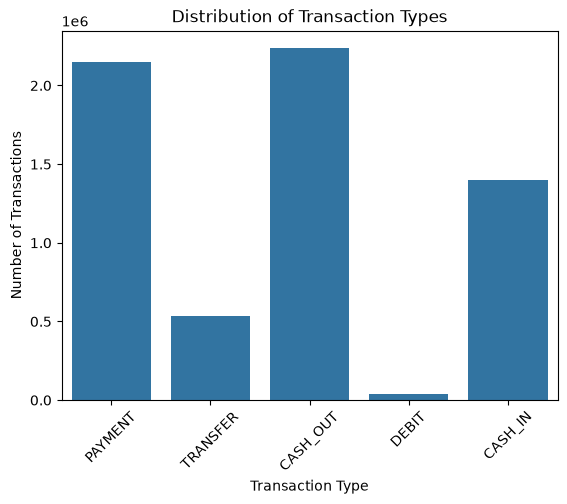

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="type")

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

In [14]:
# Analyze Fraud by Transaction Type

df.groupby("type")["isFraud"].sum()

type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64

In [15]:
df.groupby("type")["isFraud"].mean() * 100

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64

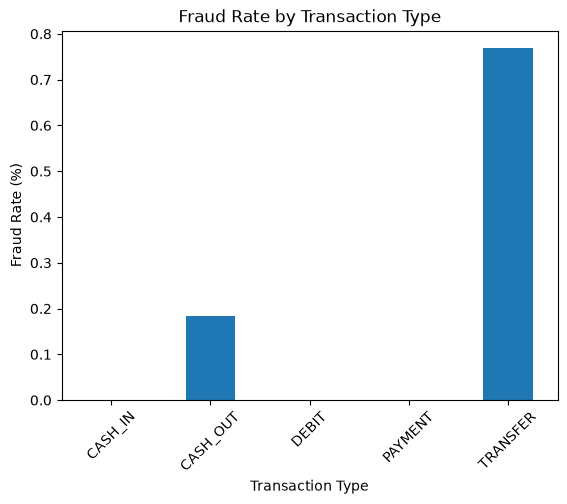

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fraud_rate = df.groupby("type")["isFraud"].mean() * 100

fraud_rate.plot(kind="bar")

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.show()

### Findings: Fraud by Transaction Type

- TRANSFER has the highest observed fraud rate at approximately 0.769%.
- CASH_OUT has an observed fraud rate of approximately 0.184%.
- No fraudulent transactions were observed in CASH_IN, DEBIT, or PAYMENT.


In [17]:
# Analyze Transaction Amounts

df.groupby("isFraud")["amount"].mean()

isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64

### Findings: Target Class Distribution

- The dataset contains 6,354,407 genuine transactions.
- The dataset contains 8,213 fraudulent transactions.
- The target variable is highly imbalanced.
- Accuracy alone is not sufficient to evaluate the fraud detection model.
- Precision, recall, F1-score, and PR-AUC will be important evaluation metrics.

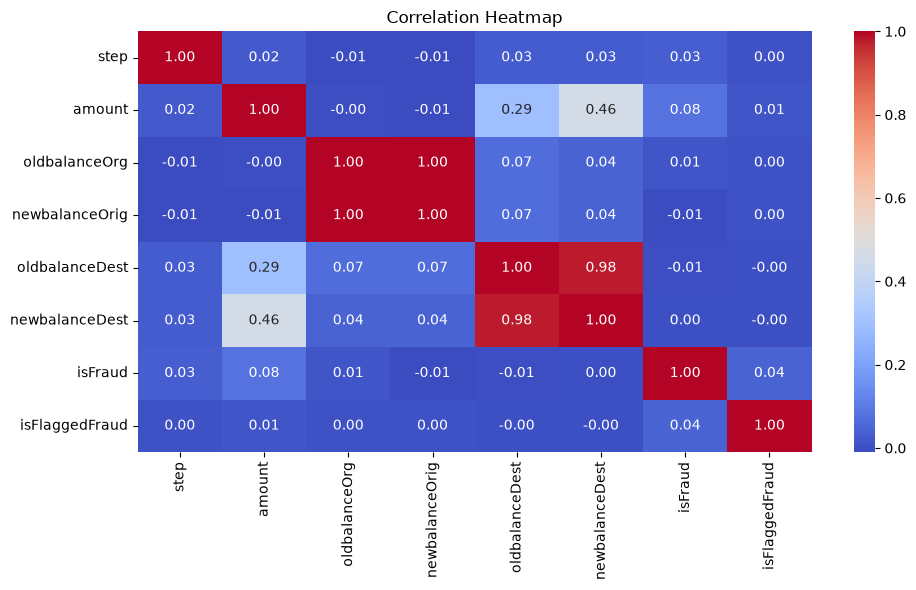

In [18]:
# Correlation Between Numerical Features

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numerical_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Data Cleaning & Feature Engineering

In [21]:
# Remove unnecessary columns
# Remove unnecessary columns
df = df.drop(columns=[
    "nameOrig",
    "nameDest",
    "isFlaggedFraud"
])

# Check remaining columns
print(df.columns)

Index(['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
       'oldbalanceDest', 'newbalanceDest', 'isFraud'],
      dtype='str')


In [22]:
# Create useful features

# Feature 1: Sender balance change
df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

# Feature 2: Expected sender balance after transaction
df["origin_expected_balance"] = (
    df["oldbalanceOrg"] - df["amount"]
)

df[[
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "origin_balance_change",
    "origin_expected_balance"
]].head()

,amount,oldbalanceOrg,newbalanceOrig,origin_balance_change,origin_expected_balance
0,9839.64,170136.0,160296.36,9839.64,160296.36
1,1864.28,21249.0,19384.72,1864.28,19384.72
2,181.00,181.0,0.00,181.00,0.00
3,181.00,181.0,0.00,181.00,0.00
4,11668.14,41554.0,29885.86,11668.14,29885.86


In [23]:
# Feature 2: Receiver balance change
df["destination_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

df[[
    "amount",
    "oldbalanceDest",
    "newbalanceDest",
    "destination_balance_change"
]].head()

,amount,oldbalanceDest,newbalanceDest,destination_balance_change
0,9839.64,0.0,0.0,0.0
1,1864.28,0.0,0.0,0.0
2,181.00,0.0,0.0,0.0
3,181.00,21182.0,0.0,-21182.0
4,11668.14,0.0,0.0,0.0


In [24]:
print("Dataset shape:", df.shape)

print("\nNew columns:")
print(df.columns.tolist())

Dataset shape: (6362620, 11)

New columns:
['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'origin_balance_change', 'origin_expected_balance', 'destination_balance_change']


In [25]:
# Encode categorical variables

# Encode the transaction type
df = pd.get_dummies(
    df,
    columns=["type"],
    dtype=int
)

# Check the result
print(df.head())
print("\nDataset shape:", df.shape)

   step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   9839.64       170136.0       160296.36             0.0   
1     1   1864.28        21249.0        19384.72             0.0   
2     1    181.00          181.0            0.00             0.0   
3     1    181.00          181.0            0.00         21182.0   
4     1  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  isFraud  origin_balance_change  origin_expected_balance  \
0             0.0        0                9839.64                160296.36   
1             0.0        0                1864.28                 19384.72   
2             0.0        1                 181.00                     0.00   
3             0.0        1                 181.00                     0.00   
4             0.0        0               11668.14                 29885.86   

   destination_balance_change  type_CASH_IN  type_CASH_OUT  type_DEBIT  \
0                         0.0             0     

In [26]:
# Split training and testing data


X = df.drop(columns=["isFraud"])
y = df["isFraud"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6362620, 14)
Target shape: (6362620,)


In [27]:
from sklearn.model_selection import train_test_split

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5090096, 14)
Testing features: (1272524, 14)
Training target: (5090096,)
Testing target: (1272524,)


In [28]:
print("Training fraud distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting fraud distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training fraud distribution:
isFraud
0    99.870926
1     0.129074
Name: proportion, dtype: float64

Testing fraud distribution:
isFraud
0    99.870887
1     0.129113
Name: proportion, dtype: float64


In [29]:
# Handle class imbalance

print("Training class distribution:")
print(y_train.value_counts())

Training class distribution:
isFraud
0    5083526
1       6570
Name: count, dtype: int64


In [30]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.5006462050159672), np.int64(1): np.float64(387.37412480974126)}


In [31]:
# Build preprocessing pipeline

# Select numerical columns
numerical_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "origin_balance_change",
    "origin_expected_balance",
    "destination_balance_change"
]

# Check the selected features
print(numerical_features)

['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'origin_balance_change', 'origin_expected_balance', 'destination_balance_change']


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create preprocessing pipeline
preprocessor = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [33]:
# Select numerical features from training and testing data
X_train_num = X_train[numerical_features]
X_test_num = X_test[numerical_features]

# Fit on training data and transform both datasets
X_train_scaled = preprocessor.fit_transform(X_train_num)
X_test_scaled = preprocessor.transform(X_test_num)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (5090096, 9)
Testing data shape: (1272524, 9)


In [34]:
# Combine Numerical and Categorical Features

# Get transaction type columns
type_columns = [
    col for col in X_train.columns
    if col.startswith("type_")
]

print("Transaction type columns:", type_columns)

Transaction type columns: ['type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [35]:
import pandas as pd

# Convert scaled numerical features back to DataFrames
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=numerical_features,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=numerical_features,
    index=X_test.index
)

# Combine numerical and transaction type features
X_train_final = pd.concat(
    [X_train_scaled_df, X_train[type_columns]],
    axis=1
)

X_test_final = pd.concat(
    [X_test_scaled_df, X_test[type_columns]],
    axis=1
)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (5090096, 14)
Final testing shape: (1272524, 14)


Train Logistic Regression

In [36]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_final, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [37]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict fraud probabilities and classes
y_pred = lr_model.predict(X_test_final)
y_prob = lr_model.predict_proba(X_test_final)[:, 1]

# Print evaluation results
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("PR-AUC:", average_precision_score(y_test, y_prob))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.96      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524

Confusion Matrix:
[[1207414   63467]
 [     64    1579]]
PR-AUC: 0.5812210076167704


### Logistic Regression — Baseline Results

- Fraud precision: approximately 0.02
- Fraud recall: approximately 0.96
- Fraud F1-score: approximately 0.05
- PR-AUC: approximately 0.5812
- The model detects most fraudulent transactions.
- However, it produces a large number of false-positive alerts.
- Further model comparison and threshold tuning are required.

In [38]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

# Train the model
dt_model.fit(X_train_final, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [39]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict fraud
y_pred_dt = dt_model.predict(X_test_final)

# Predict fraud probabilities
y_prob_dt = dt_model.predict_proba(X_test_final)[:, 1]

# Classification report
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

# PR-AUC
print("PR-AUC:", average_precision_score(y_test, y_prob_dt))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.90      1.00      0.95      1643

    accuracy                           1.00   1272524
   macro avg       0.95      1.00      0.97   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix:
[[1270707     174]
 [      6    1637]]
PR-AUC: 0.9946022181763218


In [40]:
# Create a smaller sample for hyperparameter tuning
X_tune = X_train_final.sample(
    n=500_000,
    random_state=42
)

y_tune = y_train.loc[X_tune.index]

print("Tuning sample:", X_tune.shape)
print(y_tune.value_counts())

Tuning sample: (500000, 14)
isFraud
0    499405
1       595
Name: count, dtype: int64


In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the model
dt = DecisionTreeClassifier(random_state=42)

# Define hyperparameters to test
param_dist = {
    "max_depth": [8, 10, 12, 15, 20],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "class_weight": [None, "balanced"]
}

# Configure randomized search
random_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist,
    n_iter=8,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# Run tuning
random_search.fit(X_tune, y_tune)

print("Best parameters:", random_search.best_params_)
print("Best CV PR-AUC:", random_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'min_samples_split': 10, 'min_samples_leaf': 10, 'max_depth': 12, 'class_weight': 'balanced'}
Best CV PR-AUC: 0.984050331973112


In [42]:
# Get the best model from hyperparameter tuning
best_dt_model = random_search.best_estimator_

print("Tuned Decision Tree ready!")

Tuned Decision Tree ready!


In [43]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict fraud labels and probabilities
y_pred_tuned = best_dt_model.predict(X_test_final)

y_prob_tuned = best_dt_model.predict_proba(X_test_final)[:, 1]

# Classification report
print("Tuned Decision Tree Results:")
print(classification_report(
    y_test,
    y_pred_tuned,
    zero_division=0
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

# PR-AUC
print(
    "PR-AUC:",
    average_precision_score(y_test, y_prob_tuned)
)

Tuned Decision Tree Results:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.92      0.97      0.95      1643

    accuracy                           1.00   1272524
   macro avg       0.96      0.99      0.97   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix:
[[1270750     131]
 [     47    1596]]
PR-AUC: 0.968175099577737


### Decision Tree: Baseline vs Tuned

- Original Decision Tree PR-AUC: 0.9946
- Tuned Decision Tree PR-AUC: 0.9682
- The tuned model achieved approximately 92% fraud precision.
- Fraud recall decreased to approximately 97%.
- False positives decreased from 174 to 131.
- Hyperparameter tuning improved precision but reduced recall.
- The final model will be selected after comparing additional models
  and validating performance on unseen data.



Train a Random Forest Baseline

In [44]:
from sklearn.ensemble import RandomForestClassifier

# Create a sample for baseline training
X_rf = X_train_final.sample(
    n=500_000,
    random_state=42
)

y_rf = y_train.loc[X_rf.index]

# Create Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_rf, y_rf)

print("Random Forest training completed!")

Random Forest training completed!


In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict fraud labels
y_pred_rf = rf_model.predict(X_test_final)

# Predict fraud probabilities
y_prob_rf = rf_model.predict_proba(X_test_final)[:, 1]

# Classification report
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# PR-AUC
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      1.00      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix:
[[1270879       2]
 [      4    1639]]
PR-AUC: 0.9976220116272754


In [46]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Tuned Decision Tree",
        "Random Forest"
    ],
    "PR_AUC": [
        0.581221,
        0.994602,
        0.968175,
        0.997622
    ]
})

print(results.sort_values("PR_AUC", ascending=False))

                 Model    PR_AUC
3        Random Forest  0.997622
1        Decision Tree  0.994602
2  Tuned Decision Tree  0.968175
0  Logistic Regression  0.581221


 Key Findings

- **Logistic Regression:** Achieved a PR-AUC of 0.5812 but generated a large number of false-positive alerts.
- **Decision Tree:** Achieved a PR-AUC of 0.9946, with approximately 99.6% fraud recall.
- **Tuned Decision Tree:** Achieved a PR-AUC of 0.9682. It generated fewer false positives than the original Decision Tree but missed more fraudulent transactions.
- **Random Forest:** Achieved the highest PR-AUC of 0.9976 among the evaluated models.

## Random Forest Model Selection

### Decision

Random Forest was selected as the primary candidate model based on its
baseline evaluation results.

### Baseline Performance

- PR-AUC: 0.9976
- False positives: 2
- False negatives: 4
- Training sample: 500,000 transactions

### Hyperparameter Tuning

Random Forest hyperparameter tuning was skipped to reduce computational
cost. The baseline configuration will be retained for further validation.

### Next Steps

1. Validate model performance on unseen transactions.
2. Check for potential data leakage.
3. Finalize the model evaluation.
4. Save the trained model.
5. Develop the FastAPI prediction endpoint.
6. Integrate Azure ML and MLflow for experiment tracking and deployment.

In [50]:
import joblib
from pathlib import Path

# Create model directory
model_dir = Path("../model")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model
joblib.dump(
    rf_model,
    model_dir / "random_forest.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [51]:
import joblib
from pathlib import Path

# Create model directory
model_dir = Path("../model")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    model_dir / "preprocessor.pkl"
)

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [52]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

from prediction import predict_fraud

sample_transaction = {
    "step": 1,
    "type": "TRANSFER",
    "amount": 500000,
    "oldbalanceOrg": 500000,
    "newbalanceOrig": 0,
    "oldbalanceDest": 0,
    "newbalanceDest": 500000,
}

result = predict_fraud(sample_transaction)
print(result)

{'is_fraud': 1, 'fraud_probability': 0.7697, 'result': 'Fraudulent'}
